# 🔢 Handwritten Digit Classification (MNIST)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sahilgoury7/genai-lab/blob/main/01_mnist_classification/mnist_classification.ipynb)
[![GitHub](https://img.shields.io/badge/GitHub-genai--lab-181717?style=flat&logo=github&logoColor=white)](https://github.com/sahilgoury7/genai-lab)
[![LinkedIn](https://img.shields.io/badge/LinkedIn-Sahil%20Goury-0077B5?style=flat&logo=linkedin&logoColor=white)](https://www.linkedin.com/in/sahil-goury-269107370/)

📊 **Dataset:** [Keras / Kaggle – MNIST Digits (70,000 Images)](https://www.kaggle.com/datasets/oddrationale/mnist-in-csv)  
📓 **Repository:** [sahilgoury7/genai-lab](https://github.com/sahilgoury7/genai-lab)  
💼 **Author:** [Sahil Goury](https://www.linkedin.com/in/sahil-goury-269107370/)  

---

This project is for educational purposes and beginner-friendly understanding of computer vision & deep learning fundamentals.

This project focuses on recognizing and classifying handwritten digits (0–9) using an **Artificial Neural Network (ANN)** built with **TensorFlow / Keras**.
The workflow involves loading image data, normalizing pixel values, building a feedforward neural network, and evaluating model performance.

### Pipeline Overview

- **Data Loading:** Load MNIST dataset containing 70,000 grayscale images (28×28 pixels) of digits (0–9).
- **Data Preparation:** Normalize pixel values from 0–255 range to 0–1 range for stable and faster training.
- **Modeling (ANN):**
  - `Flatten`: Converts 2D image (28×28) into 1D array of 784 values.
  - `Dense Hidden Layer`: 128 nodes with `ReLU` activation.
  - `Dense Output Layer`: 10 nodes with `Softmax` activation (probabilities for digits 0–9).
- **Compilation:** Compile model using `Adam` optimizer, `sparse_categorical_crossentropy` loss, and `accuracy` metric.
- **Training:** Train the model for 10 epochs using 20% validation split.
- **Evaluation & Prediction:** Evaluate on 10,000 unseen test images (~97% test accuracy) and generate predictions with `argmax`.
- **Analysis:** Plot loss and accuracy curves to monitor learning and check for overfitting.

### Key Highlights
- End-to-end multi-class image classification using Keras Sequential API.
- Achieves ~97% accuracy on unseen test data with a lightweight ANN architecture.
- Includes visual inspections of sample predictions and loss/accuracy curves.

### 1. Import Libraries
Importing necessary libraries including TensorFlow, Keras, Matplotlib, and NumPy for building, training, and visualizing the model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten

### 2. Load MNIST Dataset
Loading the MNIST dataset directly from Keras. It contains 60,000 training images and 10,000 test images (each image is 28x28 grayscale).

In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Sample label:", y_train[0])

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
X_train shape: (60000, 28, 28)
X_test shape: (10000, 28, 28)
Sample label: 5


### 3. Check and Visualize Data
Displaying a few sample images along with their labels to verify that the dataset loaded correctly.

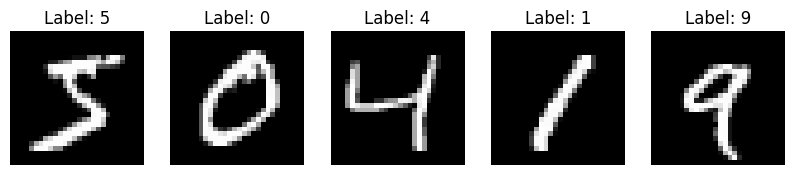

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for i in range(5):
    axes[i].imshow(X_train[i], cmap='gray')
    axes[i].set_title(f"Label: {y_train[i]}")
    axes[i].axis('off')
plt.show()

### 4. Normalize Images
Pixel values range from 0 to 255. Dividing by 255.0 scales them to a range between 0 and 1, which helps the neural network train faster and more reliably.

In [4]:
X_train = X_train / 255.0
X_test = X_test / 255.0

### 5. Build Model Architecture
Building a Sequential ANN model:
- `Flatten`: Reshapes the 28x28 2D image into a 1D vector of 784 pixels.
- `Dense (128, relu)`: Hidden layer that learns feature patterns from the images.
- `Dense (10, softmax)`: Output layer that outputs probabilities for each digit (0 to 9).

In [5]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### 6. Compile the Model
Compiling the model with the `Adam` optimizer. Since the labels are integer numbers (0 to 9), `sparse_categorical_crossentropy` is used as the loss function.

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### 7. Train the Model
Training the model for 10 epochs while setting aside 20% of the training data for validation to monitor performance during training.

In [7]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9201 - loss: 0.2818 - val_accuracy: 0.9559 - val_loss: 0.1557
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9635 - loss: 0.1255 - val_accuracy: 0.9664 - val_loss: 0.1149
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9745 - loss: 0.0857 - val_accuracy: 0.9703 - val_loss: 0.1006
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9806 - loss: 0.0639 - val_accuracy: 0.9712 - val_loss: 0.0985
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9854 - loss: 0.0487 - val_accuracy: 0.9732 - val_loss: 0.0898
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9883 - loss: 0.0383 - val_accuracy: 0.9749 - val_loss: 0.0844
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9905 - loss: 0.0302 - val_accuracy: 0.9748 - val_loss: 0.0875
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9933 - loss: 0.0238 - 

### 8. Evaluate on Test Data
Evaluating the model on 10,000 unseen test images to calculate the final test loss and test accuracy.

In [8]:
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9727 - loss: 0.1022
Test Accuracy: 97.27%


### 9. Make Predictions
Generating predictions on test images and using `argmax` to select the class with the highest predicted probability.

In [10]:
y_prob = model.predict(X_test)
y_pred = y_prob.argmax(axis=1)

# Sample prediction check
print("Predicted digit:", y_pred[0])
print("Actual digit:   ", y_test[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predicted digit: 7
Actual digit:    7


### 10. Plot Loss and Accuracy Curves
Plotting training and validation loss and accuracy across epochs to check model learning behavior and check for overfitting.

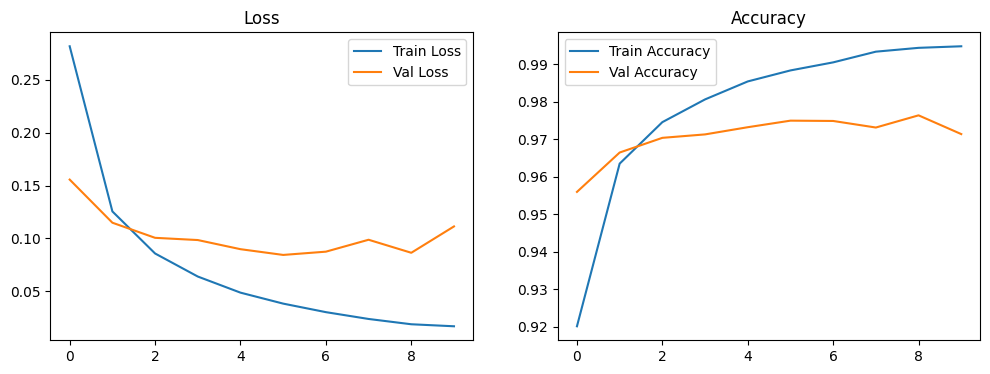

In [11]:
plt.figure(figsize=(12, 4))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy')
plt.legend()

plt.show()